In [109]:
fin = open("Maternal Health Risk Data Set (Cleaned).csv",'r')
instances = []
headers = fin.readline()
for line in fin:
    tokens = line.strip().split(',')
    instances.append(tokens)
fin.close()
instances

[['25', '130', '80', '15', '98', '86', 'high risk'],
 ['35', '140', '90', '13', '98', '70', 'high risk'],
 ['29', '90', '70', '8', '100', '80', 'high risk'],
 ['30', '140', '85', '7', '98', '70', 'high risk'],
 ['35', '120', '60', '6.1', '98', '76', 'low risk'],
 ['23', '140', '80', '7.01', '98', '70', 'high risk'],
 ['23', '130', '70', '7.01', '98', '78', 'mid risk'],
 ['35', '85', '60', '11', '102', '86', 'high risk'],
 ['32', '120', '90', '6.9', '98', '70', 'mid risk'],
 ['42', '130', '80', '18', '98', '70', 'high risk'],
 ['23', '90', '60', '7.01', '98', '76', 'low risk'],
 ['19', '120', '80', '7', '98', '70', 'mid risk'],
 ['25', '110', '89', '7.01', '98', '77', 'low risk'],
 ['20', '120', '75', '7.01', '100', '70', 'mid risk'],
 ['48', '120', '80', '11', '98', '88', 'mid risk'],
 ['15', '120', '80', '7.01', '98', '70', 'low risk'],
 ['50', '140', '90', '15', '98', '90', 'high risk'],
 ['25', '140', '100', '7.01', '98', '80', 'high risk'],
 ['30', '120', '80', '6.9', '101', '76', 

In [110]:
#clean the data
labels = []
for i in instances:
    for j in range (len(i)-1):
        i[j] = float(i[j]) 
    if i[-1] == 'high risk':
        labels.append(1)
    elif i[-1] == 'mid risk':
        labels.append(2)
    else:
        labels.append(3)
    i.remove(i[-1])
        

In [111]:
# for the feature importances, we need the headers from our dataset
feat_names = headers.strip().split(',')[:-1]
# for the ROC stuff, I figured it'd make more sense for the legends to actually say the class names
class_names = {1: 'high risk', 2: 'mid risk', 3: 'low risk'}

In [112]:
#split into train and test
from sklearn.model_selection import train_test_split
xtrain, xtest, ytrain, ytest = train_test_split(instances, labels, test_size=0.15, random_state=13)

In [113]:
#train the model
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(criterion="entropy", random_state=13)
rfc.fit(xtrain,ytrain)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",13
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap boot

In [114]:
#use cross validation
from sklearn.model_selection import cross_val_score
scores = cross_val_score(rfc, xtrain + xtest, ytrain + ytest, cv=10)
scores

array([0.7826087 , 0.64444444, 0.55555556, 0.64444444, 0.64444444,
       0.57777778, 0.62222222, 0.64444444, 0.66666667, 0.62222222])

In [115]:
prediction = rfc.predict(xtest)

In [116]:
from sklearn.metrics import accuracy_score
accuracy_score(ytest, prediction)

0.6176470588235294

In [117]:
#https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
mins = []
maxs = []
for j in range(len(feat_names)):
    column = [inst[j] for inst in instances]
    mins.append(min(column))
    maxs.append(max(column))

# it was brought up in class, but we need to scale all of our numbers,
# otherwise features like systolic blood pressure would matter way more that body temperature, 
# so now they'll all be measured from 0-1

def scale(data):
    columns = []
    for line in data:
        row = []
        for j in range(len(line)):
            row.append((line[j] - mins[j]) / (maxs[j] - mins[j]))
        columns.append(row)
    return columns

xtrainScaled = scale(xtrain)
xtestScaled = scale(xtest)

In [118]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

kValues = []
kScores = []
# we're just going through and checking a bunch of k values to see what has the best accuracy,
# then making a model with that value
for k in range(1, 52, 1): 
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, xtrainScaled, ytrain, cv=10).mean()
    kValues.append(k)
    kScores.append(score)

In [119]:
bestK = kValues[kScores.index(max(kScores))]
print("Best k:", bestK)

knn = KNeighborsClassifier(n_neighbors=bestK)
knn.fit(xtrainScaled, ytrain)
print("Accuracy:", knn.score(xtestScaled, ytest))

Best k: 14
Accuracy: 0.6617647058823529


In [120]:
#https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html#sklearn.ensemble.VotingClassifier
from sklearn.ensemble import VotingClassifier

ensemble = VotingClassifier(estimators=[('rf', rfc), ('knn', knn)], voting='soft')
ensemble.fit(xtrainScaled, ytrain)
ensamblePrediction = ensemble.predict(xtestScaled)
accuracy_score(ytest, ensamblePrediction)

0.7058823529411765

In [121]:
#use cross validation
rfScores = cross_val_score(rfc, xtrain + xtest, ytrain + ytest, cv=10)
knnScores = cross_val_score(knn, xtrain + xtest, ytrain + ytest, cv=10)
ensembleScores = cross_val_score(ensemble, xtrain + xtest, ytrain + ytest, cv=10)

print("random forest cross validation accuracy: ", rfScores)
print(rfScores.mean())
print("knn cross validation accuracy ", knnScores)
print(knnScores.mean())
print("ensemble cross validation accuracy: ", ensembleScores)
print(ensembleScores.mean())

random forest cross validation accuracy:  [0.7826087  0.64444444 0.55555556 0.64444444 0.64444444 0.57777778
 0.62222222 0.64444444 0.66666667 0.62222222]
0.6404830917874398
knn cross validation accuracy  [0.67391304 0.62222222 0.64444444 0.62222222 0.66666667 0.6
 0.6        0.71111111 0.62222222 0.66666667]
0.6429468599033815
ensemble cross validation accuracy:  [0.76086957 0.64444444 0.68888889 0.62222222 0.62222222 0.55555556
 0.62222222 0.68888889 0.64444444 0.66666667]
0.6516425120772948


In [122]:
# feature importances
# took from lab 3
rfImportance = sorted(zip(rfc.feature_importances_, feat_names), reverse=True)
for value, name in rfImportance:
    print(" ", name, round(value, 3))

import random
random.seed(13) # we can change or get rid of this at some point, but for testing I didn't want the randomness to change everytime

# i'm not sure if this is right, but in theory, if we scramble one feature at a time and see how much the cross validation accuracy drops, it'll tell us which is most important
def shuffleImportance(model, X, y, repeats):
    baseline = cross_val_score(model, X, y, cv=10).mean()
    results = []
    for i in range(len(feat_names)):
        accuracyDifferences = [] 

        for j in range(repeats):
            shuffledX = [list(inst) for inst in X] # i needed to make a copy so I'm not messing with the original data
            column = [inst[i] for inst in shuffledX]
            random.shuffle(column)

            for k in range(len(shuffledX)):
                shuffledX[k][i] = column[k]

            newScore = cross_val_score(model, shuffledX, y, cv=10).mean()
            accuracyDifferences.append(baseline - newScore)
        results.append((sum(accuracyDifferences) / len(accuracyDifferences), feat_names[i]))

    return sorted(results, reverse=True)

knnImportance = shuffleImportance(knn, xtrainScaled + xtestScaled, ytrain + ytest, 3)
ensembleImportance = shuffleImportance(ensemble, xtrainScaled + xtestScaled, ytrain + ytest, 3)

for name, results in [("knn", knnImportance), ("ensemble", ensembleImportance)]:
    print(name)
    for value, feature in results:
        print(" ", feature, round(value, 3))

  BS 0.35
  SystolicBP 0.174
  Age 0.161
  DiastolicBP 0.12
  HeartRate 0.109
  BodyTemp 0.085
knn
  BS 0.083
  DiastolicBP 0.054
  BodyTemp 0.049
  Age 0.037
  SystolicBP 0.037
  HeartRate 0.022
ensemble
  BS 0.054
  BodyTemp 0.032
  SystolicBP 0.002
  DiastolicBP -0.006
  Age -0.007
  HeartRate -0.018


In [123]:
# i don't know if this was just my python enviroment but I had to explictly download the library into my venv - Dre
# %pip install matplotlib

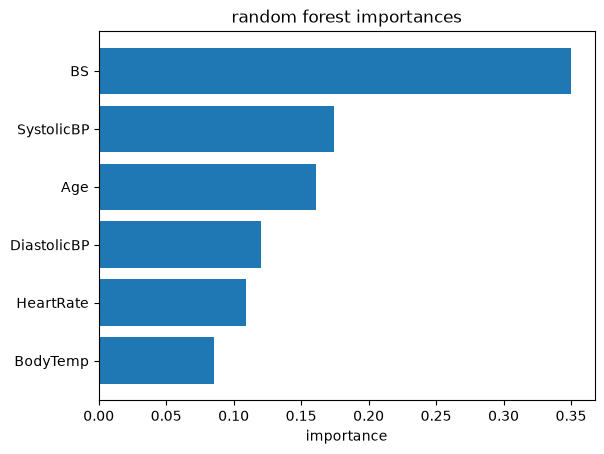

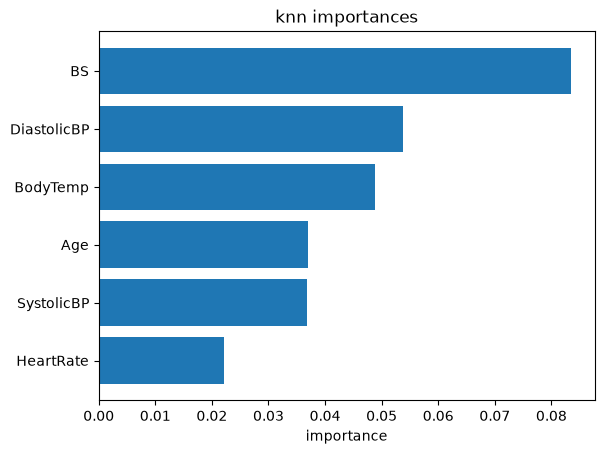

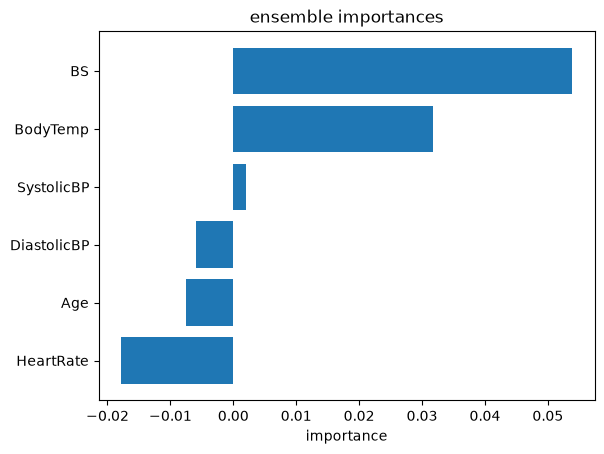

In [124]:
# some bar for the importances
import matplotlib.pyplot as plt

names = [feature for value, feature in rfImportance]
values = [value for value, feature in rfImportance]
plt.barh(names[::-1], values[::-1])
plt.xlabel("importance")
plt.title("random forest importances")
plt.show()

names = [feature for value, feature in knnImportance]
values = [value for value, feature in knnImportance]
plt.barh(names[::-1], values[::-1])
plt.xlabel("importance")
plt.title("knn importances")
plt.show()

names = [feature for value, feature in ensembleImportance]
values = [value for value, feature in ensembleImportance]
plt.barh(names[::-1], values[::-1])
plt.xlabel("importance")
plt.title("ensemble importances")
plt.show()

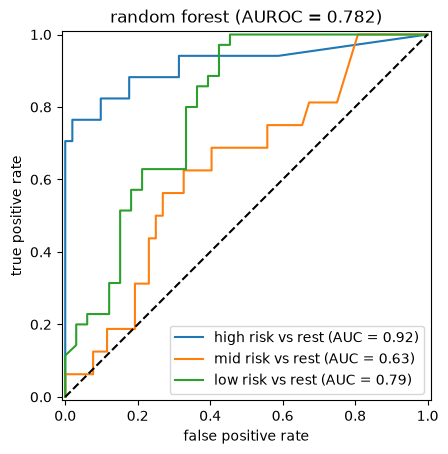

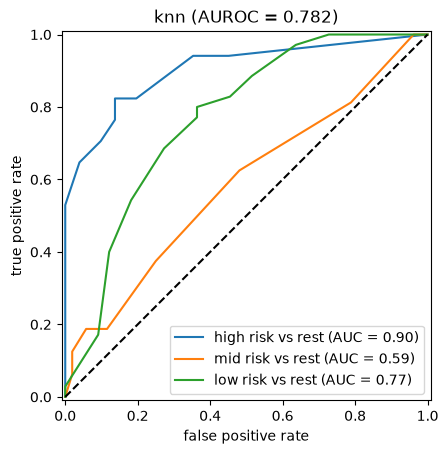

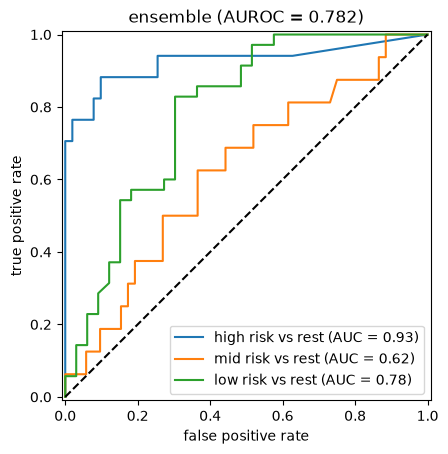

In [125]:
# roc curves and auroc
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html
from sklearn.metrics import RocCurveDisplay

probabilities = rfc.predict_proba(xtest)
AUCs = []
for riskLevel in [1, 2, 3]:
    yBinary = [1 if label == riskLevel else 0 for label in ytest]
    riskProbabilities = [p [riskLevel - 1] for p in probabilities]
    display = RocCurveDisplay.from_predictions(yBinary, riskProbabilities, ax=plt.gca(), name=class_names[riskLevel] + " vs rest")
    AUCs.append(display.roc_auc)
rfAUC = sum(AUCs) / len(AUCs)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("random forest" + " (AUROC = " + str(round(rfAUC, 3)) + ")")
plt.show()

probabilities = knn.predict_proba(xtestScaled)
AUCs = []
for riskLevel in [1, 2, 3]:
    yBinary = [1 if label == riskLevel else 0 for label in ytest]
    riskProbabilities = [p [riskLevel - 1] for p in probabilities]
    display = RocCurveDisplay.from_predictions(yBinary, riskProbabilities, ax=plt.gca(), name=class_names[riskLevel] + " vs rest")
    AUCs.append(display.roc_auc)
knnAUC = sum(AUCs) / len(AUCs)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("knn" + " (AUROC = " + str(round(rfAUC, 3)) + ")")
plt.show()

probabilities = ensemble.predict_proba(xtestScaled)
AUCs = []
for riskLevel in [1, 2, 3]:
    yBinary = [1 if label == riskLevel else 0 for label in ytest]
    riskProbabilities = [p [riskLevel - 1] for p in probabilities]
    display = RocCurveDisplay.from_predictions(yBinary, riskProbabilities, ax=plt.gca(), name=class_names[riskLevel] + " vs rest")
    AUCs.append(display.roc_auc)
ensembleAUC = sum(AUCs) / len(AUCs)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("ensemble" + " (AUROC = " + str(round(rfAUC, 3)) + ")")
plt.show()

In [126]:
# check for overfitting 
rfAll = RandomForestClassifier(criterion="entropy", random_state=13).fit(xtrainScaled + xtestScaled, ytrain + ytest)
knnAll = KNeighborsClassifier(n_neighbors=bestK).fit(xtrainScaled + xtestScaled, ytrain + ytest)
ensembleAll = VotingClassifier(estimators=[('rf', rfAll), ('knn', knnAll)], voting='soft').fit(xtrainScaled + xtestScaled, ytrain + ytest)

print("Model - Train accuracy - CV accuracy - AUROC")
print("random forest ", round(accuracy_score(ytrain + ytest, rfAll.predict(xtrainScaled + xtestScaled)), 3), " ", round(rfScores.mean(), 3), " ", round(rfAUC, 3))
print("knn ", round(accuracy_score(ytrain + ytest, knnAll.predict(xtrainScaled + xtestScaled)), 3), " ", round(knnScores.mean(), 3), " ", round(knnAUC, 3))
print("ensemble", round(accuracy_score(ytrain + ytest, ensembleAll.predict(xtrainScaled + xtestScaled)), 3), " ", round(ensembleScores.mean(), 3), " ", round(ensembleAUC, 3))

Model - Train accuracy - CV accuracy - AUROC
random forest  0.92   0.64   0.782
knn  0.714   0.643   0.753
ensemble 0.871   0.652   0.778
